In [1]:
########################################################
###################### Importierte Packete #############
########################################################

##### Visualisieren
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import rc                                                   # To use a LaTeX font
import matplotlib.cm as cm
from matplotlib.colors import rgb2hex

##### Calculations and mathematical functions
import numpy as np

##### Data Management
import pandas as pd

##### Scientific functions
import scipy
from scipy import stats
import scipy.constants as sc
from scipy import ndimage
import scipy.signal
from scipy import interpolate

from mpl_toolkits import mplot3d                                            # Um 3D Plots zu machen

import os

##### Saving/packing of data
import pickle


from sklearn import metrics

In [2]:
# importing the own functions from the scientific_utils package
from scientific_utils.general.plotting import Convert_cm_To_inch
from scientific_utils.tof_sims.io import Read_PeakList_Files

In [3]:
########## Define colours by hex code ##########
yellow = '#ffa200'
orange = '#f97625'
lightpink = '#e94a3a'
pink = '#ce1b49'
lightpurple = '#a90054'
purple = '#7e0059'
darkpurple = '#4c0057'
darkblue = '#0a004d'

########## Colours in a list to access them in a for loop ##########
colors = [yellow, orange, lightpink, pink, lightpurple, purple, darkpurple, darkblue]


########## Colour gradient with the colour package
#beginnig_color = Color("yellow")
#end_color = Color("blue")
#number_of_colorpoints = 4
#color_gradient = list(beginnig_color.range_to(end_color,number_of_colorpoints))
#print(color_gradient)


########## Cologradient with Matplotlib Colormaps
# Available colormaps: https://matplotlib.org/3.1.0/tutorials/colors/colormaps.html#ibm
number_of_colorpoints = 50 # number of colour points taken from the colour gradient with equal distance
from scientific_utils.general.plotting import my_colormap
colormap = my_colormap.resampled(number_of_colorpoints) # was: plt.get_cmap('coolwarm', number_of_colorpoints)
array_of_RGBAcolors = colormap(range(number_of_colorpoints)) # Returns the colormap as RGBA values scaled from 0 to 1
list_of_Hexcolors = [ rgb2hex(array_of_RGBAcolors[i,:]) for i in range(array_of_RGBAcolors.shape[0]) ] # Converts the scaled RGBA values to hex code and puts them in a list


In [4]:
########## Font settings for the PGF file ##########
pgf_with_latex = {                      # setup matplotlib to use latex for output
    "pgf.texsystem": "xelatex",         # change this if using xetex or lautex
    "text.usetex": False,                # use LaTeX to write all text
    #"pgf.rcfonts": False,               # don't setup fonts from rc parameters
    "font.family": "sans-serif",           # standard sans-serif font of Matplotlib
    #"mathtext.fontset": "stixsans",
    "legend.title_fontsize" : 14,
    "legend.fontsize": 10,              # Make the legend/label fonts a little smaller
    "axes.labelsize": 12,               # LaTeX default is 10pt font.
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.figsize" : Convert_cm_To_inch(1*16, 1*8),
    'savefig.dpi'         : 300,   ## figure dots per inch or 'figure'
    'savefig.facecolor'   : 'white',    ## figure facecolor when saving
    'savefig.edgecolor'   : 'white',    ## figure edgecolor when saving
    'savefig.format'      : 'png',      ## png, ps, pdf, svg
    'savefig.bbox'        : 'tight', 
    "pgf.preamble": "\n".join([
        r"\usepackage[T1]{fontenc}",    # use utf8 fonts becasue your computer can handle it :)
        r"\usepackage{fontspec}",        # plots will be generated using this preamble
        r"\usepackage{fourier}",
        r"\usepackage{unicode-math}",
        r"\usepackage[basic,italic,symbolgreek,numbers]{mathastext}"
        ])
    }

plt.rcParams.update(pgf_with_latex)

##### one style for all plots: the shared publication style (scientific_utils.general.plotting) replaces the local settings above
from scientific_utils.general.plotting import pgf_with_latex
plt.rcParams.update(pgf_with_latex)

In [5]:
input_parameters = {
    'path': './data/raw',
    'FilterByNameList': ['_uncycled_cathode'],
    'FileFormat': '.TXT',
    'StartString_of_the_wanted_Row': '\t',
    'seperation_of_the_values': '\t',
    'decimal_sign': ','
}

In [6]:
raw_data = Read_PeakList_Files(input_parameters)

./data/raw
-------------------
The following Path is selected: ./data/raw
-------------------
-------------------
Following Files found in the chosen directory: %s ['44Messung_uncycled_cathode.TXT', '45Messung_uncycled_cathode.TXT', '46Messung_uncycled_cathode.TXT', '47Messung_uncycled_cathode.TXT', '48Messung_uncycled_cathode.TXT']
-------------------
[]
['44Messung_uncycled_cathode.TXT']
['44Messung_uncycled_cathode.TXT', '45Messung_uncycled_cathode.TXT']
['44Messung_uncycled_cathode.TXT', '45Messung_uncycled_cathode.TXT', '46Messung_uncycled_cathode.TXT']
['44Messung_uncycled_cathode.TXT', '45Messung_uncycled_cathode.TXT', '46Messung_uncycled_cathode.TXT', '47Messung_uncycled_cathode.TXT']
Files found: ['44Messung_uncycled_cathode.TXT', '45Messung_uncycled_cathode.TXT', '46Messung_uncycled_cathode.TXT', '47Messung_uncycled_cathode.TXT', '48Messung_uncycled_cathode.TXT']
-------------------
In total 5 files are selected. 
The name of the files are: 
['44Messung_uncycled_cathode.TXT',

In [7]:
len(raw_data)
raw_data[0]

,Unnamed: 0,Mass (u),<No Sample Name> (44Messung_cycled_cathode),Mean,Minimum,Maximum,SD,RSD (%)
0,(null),1.009100,476528.31,476528.31,476528.31,476528.31,0.00,0.00
1,(null),6.016200,147.08,147.08,147.08,147.08,0.00,0.00
2,(null),7.017000,1608.78,1608.78,1608.78,1608.78,0.00,0.00
3,(null),8.024900,80.02,80.02,80.02,80.02,0.00,0.00
4,(null),10.013700,122.05,122.05,122.05,122.05,0.00,0.00
...,...,...,...,...,...,...,...,...
201,(null),208.854401,59.05,59.05,59.05,59.05,0.00,0.00
202,(null),210.854706,142.17,142.17,142.17,142.17,0.00,0.00
203,(null),279.865509,4042.34,4042.34,4042.34,4042.34,0.00,0.00
204,(null),379.830200,306.37,306.37,306.37,306.37,0.00,0.00


In [8]:
##### Getting highest value out of all dataframes in the list
list_of_max_value = []
list_of_min_values = []

for i in range(0, len(raw_data)):
    column_name = raw_data[i].columns[1]
    max_value = raw_data[i][column_name].max()
    list_of_max_value.append(max_value)
    min_value = raw_data[i][column_name].min()
    list_of_min_values.append(min_value)

max_value_data = max(list_of_max_value)
min_value_data = min(list_of_min_values)

print('The min Value is: %s' %min_value_data)
print('The max Value is: %s' %max_value_data)

The min Value is: 0.0
The max Value is: 379.8302


In [9]:
##### Create all possible data points between the min and max value
step_size = 0.0001
all_possible_values = np.arange(min_value_data, max_value_data, step_size)
print('Number of created datapoints is: %s' %len(all_possible_values))

Number of created datapoints is: 3798302


In [10]:
##### define dictonary 
data = {'created Mass values': all_possible_values }
##### Create Dataframe out of the Dicotnary
dataframe_new = pd.DataFrame(data)

dataframe_new

,created Mass values
0,0.00000
1,0.00010
2,0.00020
3,0.00030
4,0.00040
...,...
3798297,379.82969
3798298,379.82979
3798299,379.82989
3798300,379.82999


In [11]:
#print(dataframe_new['created Mass values'].iloc[100910])

#print(dataframe_new['created Mass values'].iloc[100909])

#print(dataframe_new['created Mass values'].iloc[100911])

In [12]:
##### Compare created mass list with Mass in the collected data and transfer the data into the new dataframe
for i in range(0, len(raw_data)):
    for k in range(0, len(raw_data[i])):
        ##### define the column names of the columns which are compared
        column_name_data = raw_data[i].columns[1]
        column_name_new_data = dataframe_new.columns[0]
        
        ##### defines the range in whoch the value must be of the newly created dataframe based on the step size
        value = raw_data[i][column_name_data].iloc[k]
        upper_value = value + (step_size*0.49)
        lower_value = value - (step_size*0.49)
        
        ##### Search for the row which has the value contained in the dataframe of the raw data
        boolean_data = dataframe_new[column_name_new_data].between(lower_value, upper_value) # gives the Rows as 'true' which fullfill the criteria
        index = dataframe_new[boolean_data].index
        #print(dataframe_new[boolean_data].index)
        
        ##### Transfer the raw Data into the new created dataframe by index
        column_name_area = raw_data[i].columns[2]
        value_area = raw_data[i][column_name_area].iloc[k]
        dataframe_new.loc[index, column_name_area] = value_area

print(len(dataframe_new))         

3798302


In [13]:
##### Define the Subset of the Dataframe by column names as a List
define_subset_column_names = []
for i in range(1, len(dataframe_new.columns)):
    define_subset_column_names.append(dataframe_new.columns[i])

##### Delete the rows in the new dataframe which only contains NaN values the defined subset
dataframe_new = dataframe_new.dropna(subset=define_subset_column_names, how='all')
#print(len(dataframe_new))    

##### Replace all NaN values wit 0
dataframe_new = dataframe_new.fillna(0)

In [14]:
##### All rows which have a smaller difference than .... between each other a sum up
# Based on: https://stackoverflow.com/questions/46732760/merge-rows-pandas-dataframe-based-on-condition
# defines the columns names from which the rows are summed up
columns_rows_summed = define_subset_column_names
# defines the group condition; Here the difference between the selected row and the next row should be smaller than 0.005
grps = dataframe_new['created Mass values'].sub(dataframe_new['created Mass values'].shift(1)).gt(0.005).cumsum()
# Perfomrs grouping
gpby = dataframe_new.groupby(grps)
# Adding the values of the 
dataframe_new = gpby.agg({'created Mass values':min}).join(gpby[columns_rows_summed].sum())
# remove index column name
dataframe_new.index.name = None

print(len(dataframe_new))

290


In [15]:
print(dataframe_new) 

     created Mass values  <No Sample Name> (44Messung_cycled_cathode)  \
0               0.000000                                   3347883.00   
1               1.009100                                    476528.31   
2               6.016200                                       147.08   
3               7.017000                                      1608.78   
4               8.024800                                        80.02   
..                   ...                                          ...   
285           221.742594                                         0.00   
286           222.738594                                         0.00   
287           246.746694                                         0.00   
288           279.862193                                      4042.34   
289           379.827190                                         0.00   

     <No Sample Name> (45Messung_cycled_cathode)  \
0                                     3307696.00   
1                  

In [16]:
old_column_names = define_subset_column_names
new_column_names = ['0 Sputter Step', '1 Sputter Step', '2 Sputter Step', '3 Sputter Step', '4 Sputter Step']
dict_column_rename = dict(zip(old_column_names, new_column_names))

dataframe_new = dataframe_new.rename(columns=dict_column_rename)
print(dataframe_new) 

     created Mass values  0 Sputter Step  1 Sputter Step  2 Sputter Step  \
0               0.000000      3347883.00      3307696.00      3290987.00   
1               1.009100       476528.31       480827.84       497148.37   
2               6.016200          147.08          126.06          141.07   
3               7.017000         1608.78         1535.01         1470.34   
4               8.024800           80.02           99.03          105.04   
..                   ...             ...             ...             ...   
285           221.742594            0.00           91.06           70.03   
286           222.738594            0.00            0.00           60.03   
287           246.746694            0.00          111.06            0.00   
288           279.862193         4042.34         2399.30         1858.28   
289           379.827190            0.00          165.12            0.00   

     3 Sputter Step  4 Sputter Step  
0        3273597.00      3272619.00  
1         5

In [17]:
##### Copy Dataframe for evaluation
data_evaluation = dataframe_new.copy()

print(data_evaluation['0 Sputter Step'])
##### Normalize the values in the columns to the first entry at 0 mass, which is the total intensity
for i in range(1, len(data_evaluation.columns)):
    name = data_evaluation.columns[i]
    data_evaluation[name] = data_evaluation[name]/data_evaluation[name].iloc[0]

print(data_evaluation)

0      3347883.00
1       476528.31
2          147.08
3         1608.78
4           80.02
          ...    
285          0.00
286          0.00
287          0.00
288       4042.34
289          0.00
Name: 0 Sputter Step, Length: 290, dtype: float64
     created Mass values  0 Sputter Step  1 Sputter Step  2 Sputter Step  \
0               0.000000        1.000000        1.000000        1.000000   
1               1.009100        0.142337        0.145366        0.151064   
2               6.016200        0.000044        0.000038        0.000043   
3               7.017000        0.000481        0.000464        0.000447   
4               8.024800        0.000024        0.000030        0.000032   
..                   ...             ...             ...             ...   
285           221.742594        0.000000        0.000028        0.000021   
286           222.738594        0.000000        0.000000        0.000018   
287           246.746694        0.000000        0.000034        0.00

In [18]:
##### Gives the Dataframe as np arrays where avery row is one np array
row_values = data_evaluation.values[1:]


In [19]:
x_values = np.arange(0,5,1)
linear_regression_slops = []

for i in range(0, len(row_values)):
    ##### Define X and Y Values
    x = x_values
    y = row_values[i][1:]
    
    ##### Perform linear regression
    linear_fit = stats.linregress(x, y)
    linear_regression_slops.append(linear_fit.slope)
    
    ##### Plot results
    #plt.plot(x_values, row_values[i][1:], label=np.array2string(row_values[i][0]) )
    #plt.legend()

<BarContainer object of 289 artists>

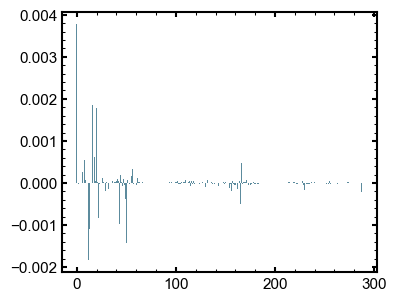

In [20]:
##### plotting the linear regression results as bar plot
x = range(len(linear_regression_slops))
plt.bar(x, linear_regression_slops)